<a href="https://colab.research.google.com/github/juliaR0/SF_10_new/blob/main/notebooks/S_Baseline_Reproduction_112126.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

running

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!git clone https://github.com/xtsoukala/dual_path.git /content/drive/MyDrive/dual_path
%cd /content/drive/MyDrive/dual_path
!ls

Cloning into '/content/drive/MyDrive/dual_path'...
remote: Enumerating objects: 25255, done.
remote: Counting objects: 100% (330/330), done.
remote: Compressing objects: 100% (143/143), done.
remote: Total 25255 (delta 187), reused 301 (delta 175), pack-reused 24925 (from 1)
Receiving objects: 100% (25255/25255), 462.95 MiB | 11.49 MiB/s, done.
Resolving deltas: 100% (19228/19228), done.
/content/drive/MyDrive/dual_path
data  img  README.md  requirements.txt	src


In [ ]:
#pip install -r requirements.txt
##removed "==" and everything after
!python --version
!sed 's/==.*//' requirements.txt > requirements_unpinned.txt
!cat requirements_unpinned.txt
!pip install -r requirements_unpinned.txt

Python 3.13.18
matplotlib
numpy
pandas
seaborn
scipy
scikits.bootstrap
joblib
torch
lz4


In [ ]:
#python src/start_dual_path.py --sim 4 --epochs 20 --cs --resdir results --lang es en
##FIX: add "!" because it was originally terminal code, not colab code
!python src/start_dual_path.py --sim 4 --epochs 20 --cs --resdir results --lang es en

INFO:root:Generating input for 4 simulations using: ./data/code-switching/lexicon.csv (lexicon) and ./data/code-switching/structures.csv (structures)
Input for sim. 2: L1 decimal fraction: 0.53, L2 decimal fraction: 0.47
Input for sim. 1: L1 decimal fraction: 0.37, L2 decimal fraction: 0.63
Input for sim. 3: L1 decimal fraction: 0.36, L2 decimal fraction: 0.64
Input for sim. 4: L1 decimal fraction: 0.5, L2 decimal fraction: 0.5
INFO:root:sim: 1, hidden: 74, compress: 56, fw: 19, epochs: 20, 
INFO:root:sim: 2, hidden: 71, compress: 54, fw: 11, epochs: 20, 
INFO:root:sim: 3, hidden: 77, compress: 59, fw: 19, epochs: 20, 
INFO:root:sim: 4, hidden: 77, compress: 59, fw: 14, epochs: 20, 


printing results from running

1  4		      code_switch_types.csv  performance.csv
2  4_performance.png  commandline_args.txt   performance_per_lang.csv
3  all_results.csv    input
simulations/results/commandline_args.txt
simulations/results/all_results.csv
simulations/results/performance.csv
simulations/results/performance_per_lang.csv
simulations/results/code_switch_types.csv
simulations/results/4_performance.png
84
10 CSV files
simulations/results/1/test.csv
simulations/results/2/test.csv
simulations/results/3/test.csv
simulations/results/4/test.csv
simulations/results/all_results.csv
simulations/results/code_switch_types.csv
simulations/results/input/lexicon.csv
simulations/results/input/structures.csv
simulations/results/performance.csv
simulations/results/performance_per_lang.csv

1 plots
simulations/results/4_performance.png
simulations/results/4_performance.png


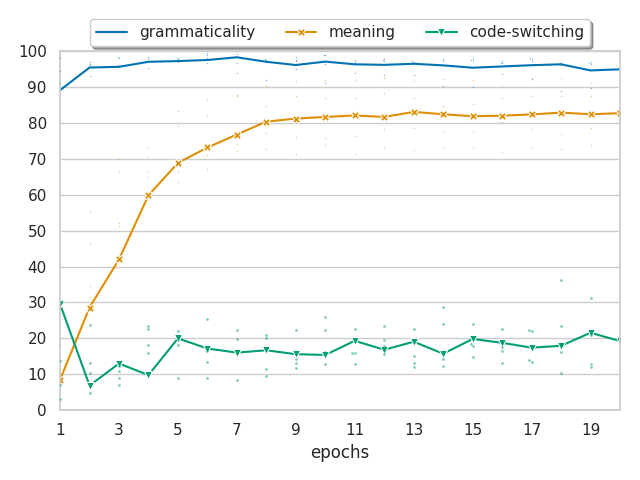

In [ ]:
!ls simulations/results
!find simulations/results -maxdepth 1 -type f | head -30     # summary files at the top level
!find simulations/results -name "*.lz4" | wc -l               # expect ~84 weight files

import glob
csvs = sorted(glob.glob('simulations/results/**/*.csv', recursive=True))
pngs = sorted(glob.glob('simulations/results/**/*.png', recursive=True))
print(len(csvs), "CSV files"); print("\n".join(csvs[:25]))
print(); print(len(pngs), "plots"); print("\n".join(pngs[:25]))

from IPython.display import Image, display
for p in pngs[:10]:
    print(p); display(Image(p, width=600))

In [ ]:
import pandas as pd
!cat simulations/results/commandline_args.txt          # the exact settings it used

perf = pd.read_csv('simulations/results/performance.csv')
print(perf.columns.tolist()); print(perf.tail(8))      # per-twin, per-epoch numbers

lang = pd.read_csv('simulations/results/performance_per_lang.csv')
print(lang.columns.tolist()); print(lang.tail(8))      # Spanish vs. English separately

test = pd.read_csv('simulations/results/1/test.csv')
print(test.columns.tolist()); test.head(10)            # likely the actual produced sentences

{
  "hidden": 80,
  "compress": null,
  "epochs": 20,
  "l2_epoch": null,
  "l2_decimal_fraction": 0.5,
  "input": null,
  "resdir": "results",
  "lexicon": "./data/code-switching/lexicon.csv",
  "structures": "./data/code-switching/structures.csv",
  "trainingset": "training.in",
  "testset": "test.in",
  "primingset": null,
  "languages": [
    "es",
    "en"
  ],
  "target_lang": [
    "es",
    "en"
  ],
  "lrate": 0.1,
  "final_lrate": 0.02,
  "momentum": 0.9,
  "set_weights": null,
  "set_weights_epoch": null,
  "fw": 15,
  "fwi": 10,
  "cognate_decimal_fraction": 0.3,
  "exclude_cognates": null,
  "cognate_list": null,
  "false_friends_lexicon": null,
  "concepts_to_evaluate": null,
  "messageless_decimal_fraction": 0,
  "generate_training_num": 2000,
  "generate_test_num": 600,
  "training_files_path": null,
  "title": null,
  "sim": 4,
  "sim_from": null,
  "sim_to": null,
  "threshold": 0,
  "config_file": false,
  "generator_timeout": 120,
  "hidden_dev": 10,
  "compress_dev

,epoch,produced_sentence,target_sentence,is_grammatical,meaning,is_code_switched,switched_type,pos_of_switch_point,first_switch_position,produced_pos,target_pos,correct_tense,correct_definiteness,message,entropy,l2_epoch,target_has_cognate,target_has_false_friend
0,0,come triste given hermana given given triste,ella tiene una llave .,False,False,True,False,False,2.0,aux adj participle noun participle participle adj,pron verb det noun .,True,True,"AGENT=pron,GRANDMOTHER;ACTION-LINKING=HAS;PATI...",5.269004 5.2710867 5.2753015 5.2776937 5.27752...,0,False,False
1,0,come anfitriona showed showed tired showed sho...,a man carries a ball .,False,False,True,False,False,0.0,aux participle verb verb adj verb verb verb,det noun verb det noun .,True,True,"AGENT=indef,MAN;ACTION-LINKING=CARRY;PATIENT=i...",5.2694583 5.2735233 5.2798166 5.281762 5.28059...,0,False,False
2,0,come boy swims pateado la has,she is tired .,False,False,True,False,False,0.0,aux noun aux participle det aux,pron verb adverb .,True,True,"AGENT=pron,CAT;ACTION-LINKING=BE;ATTR=TIRED;EV...",5.2735596 5.2764254 5.277142 5.2808867 5.27766...,0,False,False
3,0,come camarera given dado swims given dado pen ...,a kind uncle carries a book .,False,False,True,False,False,0.0,aux noun participle participle aux participle ...,det adj noun verb det noun .,True,True,"AGENT=indef,UNCLE;AGENT-MOD=KIND;ACTION-LINKIN...",5.270128 5.2652636 5.266564 5.2681575 5.268451...,0,False,False
4,0,walks gata gata gata gata gata gata gata gata ...,the waitress shows the brother a key .,False,False,True,False,False,1.0,verb noun noun noun noun noun noun noun noun noun,det noun verb det noun det noun .,True,True,"AGENT=def,WAITRESS;ACTION-LINKING=SHOW;RECIPIE...",5.270538 5.265232 5.2680387 5.2747936 5.273638...,0,False,False
5,0,come caminó gata sad gata pen gata dado gata dado,a focused grandfather is carrying the chair .,False,False,True,False,False,0.0,aux aux noun adj noun noun noun participle nou...,det adj noun aux participle det noun .,True,True,"AGENT=indef,GRANDFATHER;AGENT-MOD=FOCUSED;ACTI...",5.2724314 5.2707415 5.2720265 5.2731915 5.2763...,0,False,False
6,0,come triste llevando sad given tirado host host,el padre empuja una silla .,False,False,True,False,False,3.0,aux adj participle adj participle participle n...,det noun verb det noun .,True,True,"AGENT=def,FATHER;ACTION-LINKING=PUSH;PATIENT=i...",5.2715416 5.2740135 5.2748346 5.2806473 5.2772...,0,False,False
7,0,throwing camarera gata gata gata gata gata gat...,a man has carried the key .,False,False,True,False,False,1.0,participle noun noun noun noun noun noun noun ...,det noun aux participle det noun .,True,True,"AGENT=indef,MAN;ACTION-LINKING=CARRY;PATIENT=d...",5.2726784 5.2747307 5.2777395 5.2791524 5.2789...,0,False,False
8,0,corrido triste muestra camina gata camina swum...,a brother has pushed a ball .,False,False,True,False,False,0.0,participle adj aux aux noun aux participle aux...,det noun aux participle det noun .,True,True,"AGENT=indef,BROTHER;ACTION-LINKING=PUSH;PATIEN...",5.2675314 5.271986 5.276126 5.280345 5.2777224...,0,False,False
9,0,muerto triste gata gata él él madre madre tired,the man has kicked the pen .,False,False,True,False,False,0.0,participle adj noun noun pron pron noun noun adj,det noun aux participle det noun .,True,True,"AGENT=def,MAN;ACTION-LINKING=KICK;PATIENT=def,...",5.271266 5.274597 5.278946 5.281452 5.276804 5...,0,False,False


In [ ]:
print(t['meaning'].unique())          # shows the distinct values
print(t['meaning'].dtype)             # 'object' = text

['False' 'True' 'flex-False']
object


In [6]:
%cd /content/drive/MyDrive/dual_path
# go back into the repo folder
!ls simulations/results
# should list 1 2 3 4 and the csv/png files
import pandas as pd

t = pd.read_csv('simulations/results/1/test.csv')

# meaning holds text: 'True', 'False', or 'flex-False' -> turn it into real True/False
t['meaning_raw'] = t['meaning'].astype(str).str.strip()
t['article_or_tense_error'] = t['meaning_raw'] == 'flex-False'   # the agrammatism-type mistakes
t['meaning'] = t['meaning_raw'] == 'True'

# same fix for the other True/False columns
for col in ['is_grammatical', 'is_code_switched', 'correct_tense', 'correct_definiteness']:
    t[col] = t[col].astype(str).str.strip() == 'True'

t20 = t[t.epoch == 20]                                    # fully trained twin 1

print(len(t20), "sentences;", (~t20.meaning).sum(), "wrong")
print(t20.meaning_raw.value_counts())                     # how many True / False / flex-False
pd.set_option('display.max_colwidth', 80)
t20[~t20.meaning][['meaning_raw', 'target_sentence', 'produced_sentence']].head(15)

/content/drive/MyDrive/dual_path
1  4		      code_switch_types.csv  performance.csv
2  4_performance.png  commandline_args.txt   performance_per_lang.csv
3  all_results.csv    input
500 sentences; 70 wrong
meaning_raw
True          430
False          63
flex-False      7
Name: count, dtype: int64


,meaning_raw,target_sentence,produced_sentence
10004,flex-False,the waitress shows the brother a key .,the waitress shows a brother a key .
10011,False,la abuela amable ha llegado .,la abuela feliz has arrived .
10019,False,la camarera pateó la llave .,la camarera empujó the key .
10022,False,a sad waitress throws the book to a aunt .,a sad throws throws the book to a aunt .
10032,False,the short boy pushes the key .,the short boy has the key .
10033,False,la tía está inteligente .,la tía está atenta .
10035,False,el camarero tranquilo llegó .,el camarero arrived .
10037,False,el hermano feliz ha estornudado .,el hermano sneezed has sneezed .
10039,False,él está pequeño .,él está feliz .
10042,False,el camarero empuja una silla .,el camarero pushed a chair .


In [7]:
# which language was the target? (Spanish sentences contain Spanish articles)
t20 = t20.copy()
t20['target_lang'] = t20.target_sentence.str.split().str[0].isin(['el','la','un','una','él','ella']).map({True:'es', False:'en'})

print(t20.groupby('target_lang').meaning.mean().round(3))   # accuracy per language
print(t20.groupby('target_lang').is_code_switched.mean().round(3))   # switch rate per language
print(t20.groupby('target_lang').meaning_raw.value_counts())

target_lang
en    0.946
es    0.714
Name: meaning, dtype: float64
target_lang
en    0.022
es    0.605
Name: is_code_switched, dtype: float64
target_lang  meaning_raw
en           True           298
             False           10
             flex-False       7
es           True           132
             False           53
Name: count, dtype: int64


In [8]:
rows = []
for sim in [1, 2, 3, 4]:
    d = pd.read_csv(f'simulations/results/{sim}/test.csv')
    d = d[d.epoch == 20].copy()
    d['meaning_raw'] = d['meaning'].astype(str).str.strip()
    d['meaning'] = d['meaning_raw'] == 'True'
    d['is_code_switched'] = d['is_code_switched'].astype(str).str.strip() == 'True'
    d['lang'] = d.target_sentence.str.split().str[0].isin(['el','la','un','una','él','ella']).map({True:'es', False:'en'})
    for lang, g in d.groupby('lang'):
        rows.append({'twin': sim, 'lang': lang, 'n': len(g),
                     'meaning_%': round(100*g.meaning.mean(), 1),
                     'switch_%': round(100*g.is_code_switched.mean(), 1),
                     'flex_errors': (g.meaning_raw == 'flex-False').sum()})
summary = pd.DataFrame(rows)
summary

,twin,lang,n,meaning_%,switch_%,flex_errors
0,1,en,315,94.6,2.2,7
1,1,es,185,71.4,60.5,0
2,2,en,235,91.9,7.2,2
3,2,es,265,89.4,19.2,0
4,3,en,320,75.3,18.4,3
5,3,es,180,69.4,15.0,0
6,4,en,250,75.2,57.6,0
7,4,es,250,82.0,17.6,0
